# The Best Neighborhood in Pittsburgh
Yusuf Taniyici, Andrew Cue, Curtiss Kahmar

## Introduction
We decided the best neighborhood is one where it's easy to get around and easy to get outside. Each of us picked one thing to measure using WPRDC data.

## The Metric
- **Bike access (Yusuf):** POGOH bike-share docks per km² and walking time to the nearest station
- **Parks (Andrew):** number of parks in the neighborhood


Each one gets turned into a percentile so they're on the same scale, then we average them.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

bike = pd.read_csv("../datasets/pogoh_scores.csv")
parks_raw = pd.read_csv("../datasets/pittsburgh_parks.csv")
hoods = gpd.read_file("../datasets/neighborhoods.geojson")[["hood", "geometry"]].rename(columns={"hood": "neighborhood"})

## Bike Access

- I wanted to measure how easy it is to grab a POGOH bike in each neighborhood
- The data from WPDRC had 60 POGOH stations (docks + location) and the city's neighborhood boundaries
- I did a spatial join to match each station to the neighborhood it's in
- Only 26 of 90 neighborhoods have a station
- The score is docks per km² + walking time to the nearest station, each turned into a percentile and averaged (0–100)
- The top neighborhoods were Central Oakland, Allegheny Center, Homewood South
- The lowest neighborhoods were south and west neighborhoods, over an hour's walk from a station

In [2]:
bike[["neighborhood", "stations", "docks", "walk_min", "bike_score"]].head().round(1)

,neighborhood,stations,docks,walk_min,bike_score
0,Central Oakland,6.0,126.0,1.3,99.4
1,Allegheny Center,3.0,53.0,1.8,97.2
2,Homewood South,3.0,45.0,1.7,95.6
3,Bloomfield,4.0,64.0,1.4,94.4
4,Shadyside,5.0,87.0,2.4,93.3


## Parks
We only count listings marked as a park, so traffic islands and building grounds are not counted as a park.

In [3]:
parks = parks_raw[parks_raw["type"] == "Park"].groupby("neighborhood").size().rename("parks").reset_index()
parks.sort_values("parks", ascending=False).head()

,neighborhood,parks
55,South Side Slopes,6
5,Beechview,6
43,Mount Washington,5
30,Hazelwood,5
64,Troy Hill,5


## Combining the submetrics

In [4]:
combined = bike[["neighborhood", "bike_score"]].merge(parks, on="neighborhood", how="left")
combined["parks"] = combined["parks"].fillna(0).astype(int)

combined["bike_pct"] = combined["bike_score"].rank(pct=True) * 100
combined["parks_pct"] = combined["parks"].rank(pct=True) * 100
combined["overall"] = combined[["bike_pct", "parks_pct"]].mean(axis=1)

combined = combined.sort_values("overall", ascending=False).reset_index(drop=True)
combined.index += 1
combined.head(10).round(1)

,neighborhood,bike_score,parks,bike_pct,parks_pct,overall
1,Bloomfield,94.4,3,96.7,82.2,89.4
2,Central Business District,93.3,3,95.0,82.2,88.6
3,Lower Lawrenceville,91.7,3,92.2,82.2,87.2
4,Hazelwood,75.6,5,77.2,96.7,86.9
5,South Side Flats,90.6,3,91.1,82.2,86.7
6,East Liberty,78.3,4,80.0,92.8,86.4
7,North Shore,83.9,3,84.4,82.2,83.3
8,Crawford-Roberts,83.9,3,84.4,82.2,83.3
9,South Oakland,83.3,3,81.7,82.2,81.9
10,Garfield,83.3,3,81.7,82.2,81.9


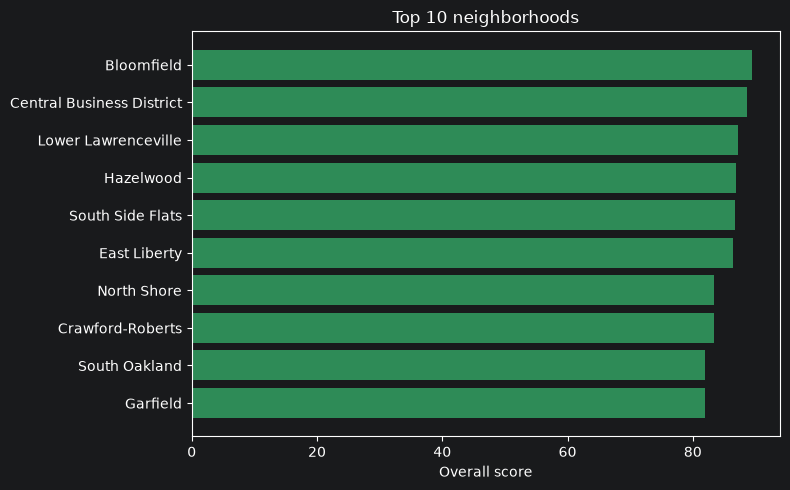

In [5]:
top10 = combined.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10["neighborhood"], top10["overall"], color="seagreen")
ax.set_xlabel("Overall score")
ax.set_title("Top 10 neighborhoods")
plt.tight_layout()
plt.show()

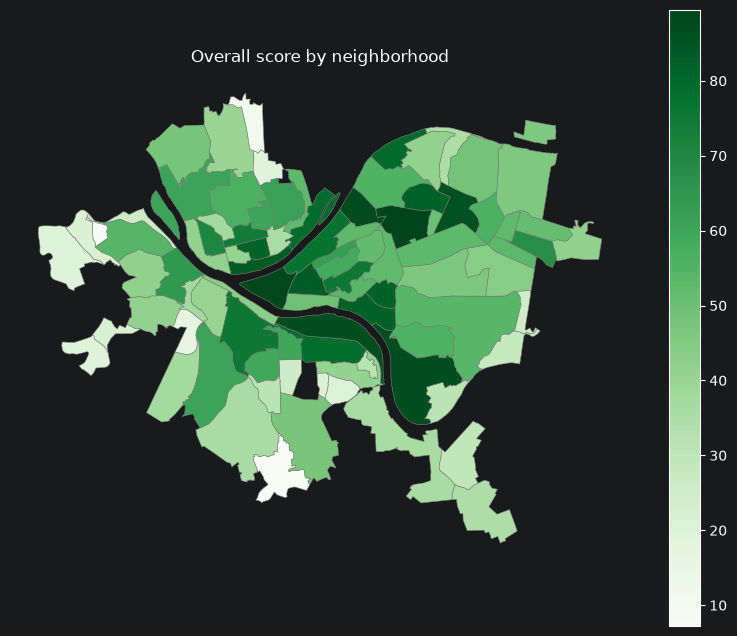

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
hoods.merge(combined, on="neighborhood").plot(
    column="overall", cmap="Greens", legend=True, edgecolor="gray", linewidth=0.4, ax=ax
)
ax.set_title("Overall score by neighborhood")
ax.set_axis_off()
plt.show()

## The Best Neighborhood
**Bloomfield** wins with a score of 89.4. It's not number 1 at either metric, but it's near the top for bike access and has more parks than most neighborhoods. Downtown comes in second.

Central Oakland is the interesting one. It's number 1 for bikes but only has 2 parks, so it falls to number 9.

At the bottom are Overbrook, Chartiers City, and Summer Hill which have no parks and are far from any bike station.
